 (accessibility-jobs)=
# Accesso a trabajos en el Área Metropolitana de Montevideo
El objetivo de esta sección es calcular la accessibilidad a trabajos que los residentes del área de estuido pueden alcanzar en 15, 30 y 45 minutos mediante transporte público y caminando. 
Sirve como línea base para identificar brechas en el acceso al empleo a nivel geográfico y para planificar el futuro transporte público.

**Este trabajo solo considera la accesibilidad con la infraestructura actual**. Una vez disponible los GTFS de la nueva propuesta, actualizaremos el análisis. 

In [2]:
from pathlib import Path
import folium
import altair as alt
import attaviz
import contextily as cx
import geopandas as gpd
import pandas as pd
from IPython.display import display


attaviz.enable()


def find_project_root(marker="pyproject.toml"):
    current = Path.cwd()
    for parent in [current, *current.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(f"Could not find {marker}")


def simplify_for_web(frame, tolerance=30):
    """Simplify projected geometry for maps without changing its extent."""
    display_frame = frame.to_crs(LOCAL_CRS).copy()
    display_frame.geometry = display_frame.geometry.simplify(
        tolerance, preserve_topology=True
    )
    return display_frame.to_crs(WGS84_CRS)


def show_full_extent(map_object):
    """Keep the map's automatic bounds so full geometries remain visible."""
    return map_object


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data"
POPULATION_PATH = DATA_PATH / "population" / "personas_ext_07_2026.csv"
NBI_PATH = DATA_PATH / "population" / "personas_nbi.csv"
ZONES_PATH = DATA_PATH / "geography-levels" / "zonas-montevideo-actualizadas-steer.gpkg"
EMPLOYMENT_PATH = DATA_PATH / "URY_montevideo_employment_predictions_relative.gpkg"
BARRIOS_PATH = DATA_PATH / "geography-levels" / "barrios_mvd_23_pg.gpkg"
SECTIONS_PATH = DATA_PATH / "geography-levels" / "sc_23_pg.gpkg"
OUTPUT_PATH = DATA_PATH / "opportunities"
POPULATION_MATRIX_PATH = OUTPUT_PATH / "accessibility_wed_08.parquet"

TILES = cx.providers.Esri.WorldGrayCanvas
LOCAL_CRS = "EPSG:32721"
WGS84_CRS = "EPSG:4326"
THRESHOLDS = (15, 30, 45)


## Fuentes de datos

| Dataset | Detalle |
|---|---|
| Personas | `personas_ext_07_2026.csv`: población del censo 2023 |
|Zonas del proyecto | `zonas-montevideo-actualizadas-steer.gpkg`: zonas creadas en base a los centroides de Steer y modificadas para que sigan las jerarquías establecidas en el censo 2023|
| Trabajos | `URY_montevideo_employment_predictions_relative.gpkg`: estimación del porcentaje de trabajos en el área de estudio. Producido por el Banco Mundial |
| Secciones censales | `sc_23_pg.gpkg`: secciones censales del censo 2023 |
|Matrices tiempo de viaje| Obtenidas a partir del GTFS de AMM y red de transporte peatonal del AMM, ver script generate_population_job_matrices.py|


### GTFS
Corresponde a las paradas del transporte público sobre la zona `Core` del proyecto. 

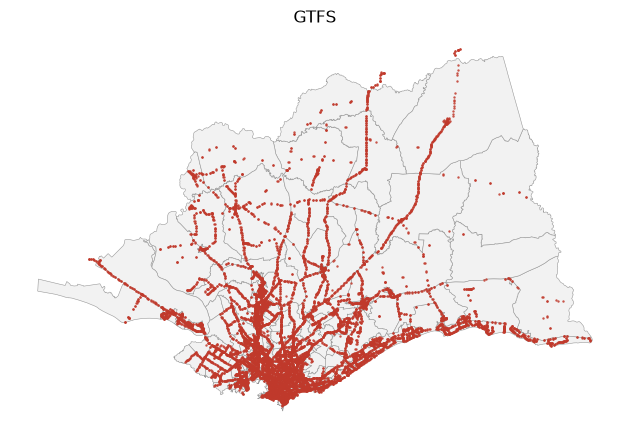

In [3]:
stops_1 = pd.read_csv('../data/GTFS/google_transit/stops.txt')
stops_2 = pd.read_csv('../data/GTFS/gtfs_20260326/stops.txt')
zonas = gpd.read_file('../data/geography-levels/zonas-a15-agg.gpkg')
stops_2 = stops_2[stops_2['stop_lat']<-10].copy()

stops_1 = gpd.GeoDataFrame(
    stops_1,
    geometry=gpd.points_from_xy(stops_1["stop_lon"], stops_1["stop_lat"]),
    crs="EPSG:4326",
)

stops_2 = gpd.GeoDataFrame(
    stops_2,
    geometry=gpd.points_from_xy(stops_2["stop_lon"], stops_2["stop_lat"]),
    crs="EPSG:4326",
)

import matplotlib.pyplot as plt

# Un mismo CRS para las tres capas, en metros.
zonas_plot = zonas[zonas['tipo_zona']=='Core'].to_crs("EPSG:32721")[['geometry']]
stops_1_plot = stops_1.to_crs(zonas_plot.crs)[["geometry"]]
stops_2_plot = stops_2.to_crs(zonas_plot.crs)[["geometry"]]
stops_all = pd.concat([stops_1_plot, stops_2_plot])

ax = zonas_plot.plot(
    facecolor="#f2f2f2",
    edgecolor="#999999",
    linewidth=0.4,
    zorder=1,
)
stops_all.plot(
    color="#c0392b",
    markersize=3,
    alpha=0.85,
    linewidth=0,
    zorder=2,
    ax = ax
)
ax.set_title('GTFS')
ax.set_axis_off()

plt.tight_layout()
plt.show()

### Ajuste de las zonas del proyecto.
La capa de empleos estimada por el Banco Mundial cubre un área menor que la del análisis. Por ello, las zonas que quedan fuera de su cobertura podrían presentar una accesibilidad muy baja o incluso nula. Sin embargo, ese resultado no necesariamente refleja la ausencia de empleos en esas zonas: es posible que haya empleos allí o en sus proximidades que la capa no representa. Por esta razón, conviene delimitar el área de estudio para que se ajuste lo mejor posible a la cobertura de la capa de empleos.

In [4]:
project_zones = (
    gpd.read_file(ZONES_PATH)
    .rename(columns={"poligono_id": "zone_id"})
    .to_crs(LOCAL_CRS)
)

employment_grid = gpd.read_file(EMPLOYMENT_PATH)
employment_grid_local = employment_grid.to_crs(LOCAL_CRS)


analysis_boundary = employment_grid_local.geometry.union_all()

# A source zone is included when its overlap with the jobs layer is greater than 90%
project_zones["zone_area_m2"] = project_zones.geometry.area
in_scope_geometry = project_zones.geometry.intersection(analysis_boundary)
project_zones["in_scope_area_m2"] = in_scope_geometry.area

project_zones["percentage_covered"] = (
    project_zones["in_scope_area_m2"] / project_zones["zone_area_m2"]
)

project_zones = project_zones.loc[project_zones["percentage_covered"] > 0.65].copy()

# Assign population to the project zones based on their CODSEG codes.
population = pd.read_csv(
    POPULATION_PATH,
    encoding="latin-1",
    dtype={
        "ID_CENSO": "str",
        "DEPARTAMENTO": "str",
        "SEGMENTO": "str",
        "SECCION": "str",
    },
)

nbi = pd.read_csv(NBI_PATH,
                encoding="latin-1",
                dtype={
                    "ID_CENSO": "str",
                    "ID_HOGAR": "str",
                    "CODSEG": "str",
                },)

population["CODSEG"] = (
    population["DEPARTAMENTO"] + population["SECCION"] + population["SEGMENTO"]
)
population_by_codseg = population.groupby("CODSEG").W.sum()

population.set_index('ID_CENSO', inplace=True)
nbi.set_index('ID_CENSO', inplace=True)
population['tiene_nbi'] = nbi['tiene_nbi']

nbi_by_codseg = population[population['tiene_nbi']==1].groupby('CODSEG').W.sum()

def population_for_codseg_list(codseg_field, pop_lookup):
    codes = [c.strip() for c in codseg_field.split(", ")]
    return pop_lookup.reindex(codes).sum(min_count=1)


project_zones["population"] = project_zones["CODSEG"].apply(
    population_for_codseg_list, pop_lookup=population_by_codseg)

project_zones["population_nbi"] = project_zones["CODSEG"].apply(
    population_for_codseg_list, pop_lookup=nbi_by_codseg)

project_zones["population_density_per_km2"] = project_zones["population"] / (
    project_zones["zone_area_m2"] / 1_000_000
)
project_zone_ids = set(project_zones["zone_id"])


/var/folders/c5/zm5_fc5x3g92v0z0h0c5mwfw0000gp/T/ipykernel_48228/2066400988.py:25: DtypeWarning: Columns (14,151) have mixed types. Specify dtype option on import or set low_memory=False.
  population = pd.read_csv(


### Distribución espacial de población y trabajos

Los siguientes mapas muestran:
- Densidad poblacional: calculada con los datos del censo 2023 sobre las zonas de estudio.

- Distribución de empleos: El mapa de empleos representa el porcentaje de empleos correspondiente a cada hexágono, de modo que la suma de los porcentajes de todos los hexágonos es igual al 100%.

In [7]:
stops_8_octubre = gpd.read_file("../data/new-infrastructure/Paradas troncal 8 de octubre.kmz", driver="KML")
stops_italia = gpd.read_file("../data/new-infrastructure/Paradas Troncal Av. Italia.kmz", driver="KML")

In [8]:
population_density_map = show_full_extent(
    simplify_for_web(project_zones).explore(
        column="population_density_per_km2",
        cmap="YlGnBu",
        legend=True,
        scheme="Quantiles",
        k=5,
        tooltip=[
            "zone_id",
            "population",
            "population_density_per_km2",
        ],
        tiles=TILES,
        legend_kwds={"caption": "Densidad poblacional (personas/km²)"},
        style_kwds={"weight": 0.4, "color": "white", "fillOpacity": 0.75},
        missing_kwds={"color": "lightgrey", "label": "Sin Población"},
    )
)

stops_8_octubre.to_crs(WGS84_CRS).explore(m=population_density_map, color="#002244", name="Paradas 8 de Octubre")
stops_italia.to_crs(WGS84_CRS).explore(m=population_density_map, color="#009FDA", name="Paradas Av. Italia")

legend_html = """
<div style="
    position: fixed;
    bottom: 30px;
    left: 30px;
    z-index: 9999;
    background-color: white;
    border: 1px solid grey;
    border-radius: 4px;
    padding: 10px;
    font-size: 13px;
">
    <b>Paradas</b><br>
    <span style="color: #002244;">●</span> Paradas 8 de Octubre<br>
    <span style="color: #009FDA;">●</span> Paradas Av. Italia
</div>
"""

population_density_map.get_root().html.add_child(folium.Element(legend_html))
display(population_density_map)


employment_context_map = show_full_extent(
    simplify_for_web(employment_grid, tolerance=20).explore(
        column="pred_relative_employment",
        cmap="Purples",
        legend=True,
        # scheme="Quantiles",
        k=5,
        tooltip=["grid_id", "pred_relative_employment"],
        tiles=TILES,
        legend_kwds={"caption": "Proporción de empleos (puntos porcentuales)"},
        style_kwds={"weight": 0.2, "color": "#756bb1", "fillOpacity": 0.75},
    )
)

stops_8_octubre.to_crs(WGS84_CRS).explore(m=employment_context_map, color="#002244", name="Paradas 8 de Octubre")
stops_italia.to_crs(WGS84_CRS).explore(m=employment_context_map, color="#009FDA", name="Paradas Av. Italia")

employment_context_map.get_root().html.add_child(folium.Element(legend_html))
display(employment_context_map)

## Accesibilidad
**Definición**
La accesibilidad se calcula como la suma de los porcentajes de empleos que pueden alcanzarse desde cada ubicación en un máximo de 15, 30 y 45 minutos de viaje.

El análisis considera viajes iniciados un miércoles entre las 8:00 y las 9:00. Para calcular el tiempo total de viaje, se tienen en cuenta:

el tiempo de acceso y egreso a pie;
el tiempo de espera en la parada, estimado como la mitad del intervalo entre servicios;
el tiempo de viaje dentro del vehículo.
Además, se compara la duración del viaje a pie con la del viaje en transporte público. Si caminar requiere menos tiempo, se selecciona esa alternativa.

In [9]:
if not POPULATION_MATRIX_PATH.exists():
    raise FileNotFoundError(
        f"Existing baseline matrix is missing: {POPULATION_MATRIX_PATH}"
    )

population_matrix = pd.read_parquet(POPULATION_MATRIX_PATH)
required_matrix_columns = {"from_id", "to_id", "p50"}
missing_matrix_columns = required_matrix_columns.difference(population_matrix.columns)
if missing_matrix_columns:
    raise ValueError(
        "Baseline matrix is missing columns: "
        + ", ".join(sorted(missing_matrix_columns))
    )

destination_ids_without_matrix_rows = sorted(
    set(employment_grid["grid_id"]) - set(population_matrix["to_id"])
)

matrix_summary = pd.DataFrame(
    {
        "measure": [
            "origin-destination pairs",
            "origins",
            "destinations",
            "employment hexagons without destination rows",
            "non-null p50 pairs",
        ],
        "value": [
            len(population_matrix),
            population_matrix["from_id"].nunique(),
            population_matrix["to_id"].nunique(),
            len(destination_ids_without_matrix_rows),
            population_matrix["p50"].notna().sum(),
        ],
    }
)
matrix_summary


,measure,value
0,origin-destination pairs,2385735
1,origins,627
2,destinations,3805
3,employment hexagons without destination rows,3
4,non-null p50 pairs,1784830


### Cálculo de accesibilidad
Para cada origen *i*, destino *j*, y umbral *t* en `{15, 30, 45}`, la accesibilidad se calcula como:

$$
A_i(t)
=
\sum_j \left[
\mathrm{trabajos\_propocion}_j
\times
\mathbf{1}\!\left(\mathrm{p50}_{ij} \leq t\right)
\right]
$$

Donde $p50_{ij}$ es la mediana del tiempo de viaje entre *i* - *j*. A lo largo del período de estudio —una hora en este caso—, los tiempos de viaje pueden variar para cada par origen-destino (OD). En este análisis, usamos la mediana como valor representativo del tiempo de viaje de cada par. Aunque esta elección es arbitraria, busca evitar una estimación excesivamente optimista o pesimista de la métrica.

La accesibilidad, por sí sola, mide cuántos puntos de interés pueden alcanzarse desde cada lugar del área de estudio, independientemente de que allí vivan personas. Aunque este dato puede ser útil, muchas veces necesitamos conocer la accesibilidad en relación con la población de la ciudad. En esos casos, calculamos la accesibilidad ponderada por la población: así, los lugares con más habitantes tienen mayor peso en el cálculo del promedio regional.

El valor de **accesibilidad ponderado por población** para el área de estudio resulta:

$$
A_{\mathrm{poblacion}}(t)
=
\frac{\sum_i \left[\mathrm{poblacion}_i \times A_i(t)\right]}
     {\sum_i \mathrm{poblacion}_i}
$$


#### El modelo se basa en los siguientes supuestos:

a) Los empleos se distribuyen uniformemente dentro de los polígonos de análisis.

b) El tiempo de viaje dentro del polígono es despreciable en nuestro análisis y los cálculos se realizan utilizando el centroide. 

b) Se supone que el sistema de transporte público opera según el horario previamente definido y que el análisis es determinístico.

d) Se fija una velocidad de caminata de **chequear** km/h para todas las personas usuarias, en todas las calles y todos los polígonos.

e) Se supone que todas las calles de la red, obtenidas de OpenStreetMap, son transitables a pie.

```
{note} En este caso, el tiempo de viaje se calcula entre el centroide de cada polígono perteneciente a la zonificación del área de estudio y el centroide de cada hexágono de la capa de distribución de trabajos. 
```

In [10]:
def accessibility_scores(matrix):
    """Return job-share accessibility columns for every matrix origin."""
    pairs = matrix.merge(
        employment_grid[["grid_id", "pred_relative_employment"]],
        left_on="to_id",
        right_on="grid_id",
        how="left",
        validate="many_to_one",
    )
    score_columns = [f"accessibility_{minutes}min" for minutes in THRESHOLDS]
    scored_pairs = pairs.assign(
        **{
            f"accessibility_{minutes}min": pairs["pred_relative_employment"]
            .fillna(0)
            .where(pairs["p50"].le(minutes), 0)
            for minutes in THRESHOLDS
        }
    )
    return scored_pairs.groupby("from_id", as_index=False)[score_columns].sum()


def weighted_accessibility(frame, population_column="population"):
    """Return conservative and routed-denominator weighted job accessibility."""
    populated = frame[population_column].notna()
    routed = populated & frame["has_any_route"]
    denominator = frame.loc[populated, population_column].sum()
    routed_denominator = frame.loc[routed, population_column].sum()
    results = {
        "population_denominator": denominator,
        "routed_population_denominator": routed_denominator,
    }
    for minutes in THRESHOLDS:
        column = f"accessibility_{minutes}min"
        results[f"accessibility_{minutes}min_pct"] = (
            frame.loc[populated, population_column]
            * frame.loc[populated, column].fillna(0)
        ).sum() / denominator
        results[f"routed_accessibility_{minutes}min_pct"] = (
            frame.loc[routed, population_column] * frame.loc[routed, column]
        ).sum() / routed_denominator
    return results


In [11]:
zone_matrix = population_matrix.loc[
    population_matrix["from_id"].isin(project_zone_ids)
].copy()
zone_scores = accessibility_scores(zone_matrix).rename(columns={"from_id": "zone_id"})

project_zone_accessibility = project_zones.merge(zone_scores, on="zone_id", how="left")


### ¿Cuántos trabajos puede alcanzar cada persona?
Los siguientes mapas muestran el porcentaje de empleos que pueden alcanzarse desde cada zona de análisis dentro de los distintos umbrales de tiempo de viaje.

#### Zonas del proyecto

In [12]:
accessibility_bar = (
    alt.Chart(project_zone_accessibility)
    .mark_bar(color=attaviz.SEQ_PURPLE[-2])
    .encode(
        x=alt.X(
            "threshold_minutes:O",
            title="Travel-time threshold (minutes)",
            sort=list(THRESHOLDS),
        ),
        y=alt.Y(
            "jobs_reachable_pct:Q",
            title="Modeled jobs reachable (%)",
            scale=alt.Scale(domain=[0, 100]),
        ),
        tooltip=[
            alt.Tooltip("threshold_minutes:O", title="Minutes"),
            alt.Tooltip(
                "jobs_reachable_pct:Q",
                title="All in-scope population",
                format=".2f",
            ),
        ],
    )
    .properties(
        title="Population-weighted access within the jobs layer",
        width=560,
        height=320,
    )
)
accessibility_labels = accessibility_bar.mark_text(
    align="center", baseline="bottom", dy=-6, color=attaviz.TEXT
).encode(text=alt.Text("jobs_reachable_pct:Q", format=".2f"))
display()

for threshold in THRESHOLDS:
    result_map = project_zone_accessibility.copy()
    result_map[f"jobs_reachable_{threshold}min_pct"] = result_map[
        f"accessibility_{threshold}min"
    ]
    accessibility_explore = show_full_extent(
        simplify_for_web(result_map).explore(
            column=f"jobs_reachable_{threshold}min_pct",
            cmap="YlOrRd",
            legend=True,
            tooltip=[
                "zone_id",
                "tipo_zona",
                "population",
                "population_density_per_km2",
                "accessibility_15min",
                "accessibility_30min",
                "accessibility_45min",
            ],
            tiles=TILES,
            legend_kwds={"caption": f"Empleos accesibles en {threshold} minutos (%)"},
            style_kwds={"weight": 0.35, "color": "white", "fillOpacity": 0.75},
            missing_kwds={
                "color": "lightgrey",
                "label": "No valid route in matrix",
            },
        )
    )
    accessibility_explore = stops_8_octubre.to_crs(WGS84_CRS).explore(m=accessibility_explore, color="#002244", name="Paradas 8 de Octubre")
    accessibility_explore = stops_italia.to_crs(WGS84_CRS).explore(m=accessibility_explore, color="#009FDA", name="Paradas Av. Italia")
    accessibility_explore.get_root().html.add_child(folium.Element(legend_html))
    display(accessibility_explore)


In [13]:
# Columnas de accesibilidad a propagar a cada persona
acc_cols = [f"accessibility_{m}min" for m in THRESHOLDS]

# Base: una fila por zona con las variables que querés conservar
zone_people = project_zone_accessibility[
    ["zone_id", "seccion_codigo", "population", "population_nbi", *acc_cols]
].dropna(subset=["population"]).copy()

# Pasá la población a entero (W puede ser float)
zone_people["population_int"] = zone_people["population"].round().astype(int)

# Un registro por persona
people = zone_people.loc[
    zone_people.index.repeat(zone_people["population_int"])
].reset_index(drop=True)

# Marca NBI: las primeras N personas de cada zona (N = population_nbi) son NBI=1
people["person_in_zone"] = people.groupby("zone_id").cumcount()
people["tiene_nbi"] = (
    people["person_in_zone"] < people["population_nbi"].fillna(0).round().astype(int)
).astype(int)

people = people.drop(columns=["population", "population_int", "population_nbi",
                              "person_in_zone"])

In [14]:
people.loc[people['tiene_nbi']==1, 'nb'] = 'NBI'
people.loc[people['tiene_nbi']==0, 'nb'] = 'NBS'

#### ¿Cómo cambia la accessibilidad por grupo socioeconómico?

El siguiente análisis busca identificar diferencias en la accesibilidad entre las personas con necesidades básicas insatisfechas (NBI) y aquellas sin necesidades básicas insatisfechas, es decir, con necesidades básicas satisfechas (NBS).

**Metodología**

1. Se estima la condición de NBI o NBS de cada persona del área de estudio. Como se explica en detalle en esta [sección](draft-nbi), el indicador de NBI no fue publicado oficialmente para el Censo 2023. Por ello, el equipo del Banco Mundial lo estimó aplicando la metodología del Censo 2011 a los datos del Censo 2023.
2. Se calcula la accesibilidad a los empleos en umbrales de viaje de 15, 30 y 45 minutos para cada persona del área de estudio.

Con la información de NBI/NBS y de accesibilidad para cada persona, comparamos la distribución de la accesibilidad entre ambos grupos.

El gráfico siguiente presenta tres conjuntos de diagramas de caja (*boxplots*), uno por cada umbral de viaje: 15, 30 y 45 minutos. Cada diagrama resume la distribución de la accesibilidad entre las personas del área de estudio:

- El borde inferior de la caja representa el primer cuartil (Q1). El 25 % de las personas con menor accesibilidad tiene valores iguales o inferiores a este.
- La línea dentro de la caja representa la mediana (Q2): el 50 % de las personas tiene valores iguales o inferiores a ella.
- El borde superior de la caja representa el tercer cuartil (Q3). El 25 % de las personas con mayor accesibilidad tiene valores iguales o superiores a este.

Para facilitar la comparación, el resultado se presenta por separado para las personas con NBS y con NBI.

Como se observa en el gráfico, las personas con NBI tienden a presentar menores niveles de accesibilidad. Si nos centramos en el umbral de 45 minutos, vemos que:

- Entre las personas con NBS, el 25 % con menor accesibilidad puede acceder, como máximo, al 6,3 % de los empleos del área de estudio. Entre las personas con NBI, el valor correspondiente es del 3,3 %.
- Entre las personas con NBS, el 25 % con mayor accesibilidad puede acceder, como mínimo, al 85,7 % de los empleos. Entre las personas con NBI, ese valor es del 55 %.
- La mediana de accesibilidad es del 40,2 % para las personas con NBS y del 18,3 % para las personas con NBI. Es decir, la mitad de cada grupo tiene una accesibilidad igual o inferior a esos valores.

Por último, calculamos la accesibilidad promedio para cada grupo socioeconómico y para la región de estudio, considerando los tres umbrales de viaje. Los resultados indican que, en el umbral de 45 minutos, en promedio, en el área de estudio las personas acceden a aproximadamente el 38% de los empleos. Si desagregamos por grupo socioeconómico, las personas con NBS acceden, en promedio, al 41 % de los empleos, frente al 29 % entre las personas con NBI.

In [15]:
alt.data_transformers.enable("vegafusion")

boxplots = []
for minutes in THRESHOLDS:
    column = f"accessibility_{minutes}min"
    chart = (
        alt.Chart(
            people[["nb", column]]
            .rename(columns={"nb": "Group", column: "Jobs reachable (%)"})
            .dropna()
        )
        .mark_boxplot(size=60, color=attaviz.SEQ_PURPLE[-2], outliers=False)
        .encode(
            x=alt.X("Group:N", title=None, sort=["NBS", "NBI"]),
            y=alt.Y("Jobs reachable (%):Q", scale=alt.Scale(domain=[0, 100])),
        )
        .properties(title=f"{minutes} min", width=190, height=300)
    )
    boxplots.append(chart)

boxplots = (
    alt.hconcat(*boxplots)
    .properties(
        title=alt.Title(
            "La accesibilidad al trabajo varía según el perfil socioeconómico de la población",
            subtitle="Distribución del porcentaje de empleos alcanzables dentro de cada umbral de tiempo de viaje",
        )
    )
    .configure(numberFormat=".1f")
)
display(boxplots)

alt.HConcatChart(...)

In [16]:
project_zone_accessibility['population_nbs'] = project_zone_accessibility['population'] - project_zone_accessibility['population_nbi']

In [22]:
df = pd.DataFrame(index = [f'Accessibility in {threshold} min' for threshold in THRESHOLDS], columns = ['NBS', 'NBI'])
for threshold in THRESHOLDS:
    for group in ['NBS', 'NBI']:
        if group == 'NBS':
            population_col = 'population_nbs'
        else:
            population_col = 'population_nbi'
        df.loc[f'Accessibility in {threshold} min', group] = round(((project_zone_accessibility[population_col]*project_zone_accessibility[f'accessibility_{threshold}min'])/(project_zone_accessibility[population_col].sum())).sum(), 2)
    df.loc[f'Accessibility in {threshold} min', 'ADI'] = round(((project_zone_accessibility['population']*project_zone_accessibility[f'accessibility_{threshold}min'])/(project_zone_accessibility['population'].sum())).sum(), 2)
df

,NBS,NBI,ADI
Accessibility in 15 min,2.23,1.32,2.01
Accessibility in 30 min,16.74,10.07,15.09
Accessibility in 45 min,40.86,29.11,37.95


### Accesibilidad por hexágonos
En el análisis anterior utilizamos los polígonos de la zonificación propuesta por Steer por dos motivos: (1) para que los resultados fueran comparables con los del análisis de Kido Dynamics y (2) porque se construyeron a partir de fracciones censales, lo que facilita calcular la población y las características socioeconómicas de cada zona.

Sin embargo, como estos polígonos tienen tamaños diferentes, su uso puede introducir un sesgo. Un polígono de mayor tamaño podría presentar una accesibilidad más alta simplemente porque contiene más empleos, y no necesariamente porque esté mejor conectado con el resto de las zonas.

El uso de polígonos regulares, como los hexágonos de la capa de empleos, permite reducir este posible sesgo. Por este motivo, realizamos un segundo análisis. Los mapas siguientes muestran la accesibilidad calculada para cada hexágono, expresada como el porcentaje de empleos que puede alcanzarse desde allí dentro de cada umbral de tiempo de viaje.

In [20]:
baseline_hex_matrix_path = OUTPUT_PATH / "accessibility_grid_wed_08.parquet"
if not baseline_hex_matrix_path.exists():
    raise FileNotFoundError(baseline_hex_matrix_path)

baseline_hex_matrix = pd.read_parquet(baseline_hex_matrix_path)
baseline_hex_matrix[["from_id", "to_id"]] = baseline_hex_matrix[
    ["from_id", "to_id"]
].astype(str)
baseline_hex_ids = employment_grid["grid_id"].astype(str).tolist()
baseline_hex_scores = accessibility_scores(baseline_hex_matrix).rename(
    columns={"from_id": "grid_id"}
)
# baseline_hex_coverage = routing_coverage(baseline_hex_matrix, baseline_hex_ids).rename(
#     columns={"origin_id": "grid_id"}
# )
hex_scores = employment_grid_local[
    ["grid_id", "pred_relative_employment", "geometry"]
].copy()
hex_scores["grid_id"] = hex_scores["grid_id"].astype(str)
hex_scores = hex_scores.merge(
    baseline_hex_scores, on="grid_id", how="left", validate="one_to_one"
)
assert (
    hex_scores["accessibility_15min"].fillna(0)
    <= hex_scores["accessibility_30min"].fillna(0)
).all()
assert (
    hex_scores["accessibility_30min"].fillna(0)
    <= hex_scores["accessibility_45min"].fillna(0)
).all()

In [30]:
hex_map_data = simplify_for_web(hex_scores, tolerance=20)
for minutes in THRESHOLDS:
    column = f"accessibility_{minutes}min"
    hex_map = show_full_extent(
        hex_map_data.explore(
            column=column,
            cmap="YlOrRd",
            legend=True,
            tooltip=[
                "grid_id",
                "pred_relative_employment",
                "accessibility_15min",
                "accessibility_30min",
                "accessibility_45min",
            ],
            tiles=TILES,
            legend_kwds={
                "caption": f"Empleos accesibles en {minutes} min, tomando como referencia un miércoles 8:00 hs (puntos porcentuales)"
            },
            style_kwds={
                "weight": 0.2,
                "color": "#756bb1",
                "fillOpacity": 0.75,
            },
            missing_kwds={
                "color": "lightgrey",
                "label": "Origin missing from matrix",
            },
        )
    )
    hex_map = stops_8_octubre.to_crs(WGS84_CRS).explore(m=hex_map, color="#002244", name="Paradas 8 de Octubre")
    hex_map = stops_italia.to_crs(WGS84_CRS).explore(m=hex_map, color="#009FDA", name="Paradas Av. Italia")
    hex_map.get_root().html.add_child(folium.Element(legend_html))
    display(hex_map)


### Accesibilidad por sección censal

Finalmente, calculamos la accessibilidad ponderada por la población para cada sección censal. Como podemos observar, las secciones censales del centro del AMM son las que cuentan con los mayores números de accesibilidad. 

In [23]:
def include_if_significant_overlap(frame, analysis_boundary, id_col):
    frame = frame.to_crs(LOCAL_CRS)
    frame["zone_area_m2"] = frame.geometry.area
    in_scope_geometry = frame.geometry.intersection(analysis_boundary)
    frame["in_scope_area_m2"] = in_scope_geometry.area

    frame["percentage_covered"] = frame["in_scope_area_m2"] / frame["zone_area_m2"]

    frame = frame.loc[frame["percentage_covered"] > 0.65].copy()
    return set(frame[id_col])

In [ ]:
census_sections = (
    gpd.read_file(SECTIONS_PATH)
    .filter(["CODSECC", "SECC", "geometry"])
    .to_crs(LOCAL_CRS)
)

codsec = include_if_significant_overlap(census_sections, analysis_boundary, "CODSECC")
census_sections = census_sections[census_sections["CODSECC"].isin(codsec)].copy()
census_sections.set_index("CODSECC", inplace=True)


def population_weighted_accessibility(group, acc_var):
    return (group[acc_var] * group["population"]).sum() / group["population"].sum()


for minutes in THRESHOLDS:
    accessibility_per_seccion = project_zone_accessibility.groupby(
        "seccion_codigo"
    ).apply(population_weighted_accessibility, acc_var=f"accessibility_{minutes}min")
    census_sections[f"accessibility_{minutes}min"] = accessibility_per_seccion
census_sections = census_sections.reindex(
    set(project_zone_accessibility.seccion_codigo)
).copy()

In [31]:
seccion_map_data = simplify_for_web(census_sections, tolerance=20)
for minutes in THRESHOLDS:
    column = f"accessibility_{minutes}min"
    section_map = show_full_extent(
        seccion_map_data.explore(
            column=column,
            cmap="YlOrRd",
            legend=True,
            tooltip=[
                "SECC",
                "accessibility_15min",
                "accessibility_30min",
                "accessibility_45min",
            ],
            tiles=TILES,
            legend_kwds={
                "caption": f"Empleos accesibles en {minutes} min, tomando como referencia un miércoles 8:00 hs (puntos porcentuales)"
            },
            style_kwds={
                "weight": 0.2,
                "color": "#756bb1",
                "fillOpacity": 0.75,
            },
        )
    )
    section_map = stops_8_octubre.to_crs(WGS84_CRS).explore(m=section_map, color="#002244", name="Paradas 8 de Octubre")
    section_map = stops_italia.to_crs(WGS84_CRS).explore(m=section_map, color="#009FDA", name="Paradas Av. Italia")
    section_map.get_root().html.add_child(folium.Element(legend_html))
    display(section_map)